# Busca Gulosa no mapa de League of Legends

**Aplicação prática de busca informada em grafo**

Este notebook aplica a **Busca Gulosa (Greedy Best-First Search)** a um grafo baseado no mapa de *League of Legends*. O mapa, com seus nós, conexões e coordenadas, foi desenvolvido separadamente e exportado para `mapa_lol.json`. A implementação do algoritmo está no arquivo `busca_gulosa.py`, com a fila de prioridade construída manualmente em `heap.py`.

**Arquivos necessários na mesma pasta:** `aplicacao_bgulosa_final.ipynb`, `mapa_lol.json`, `busca_gulosa.py` e `heap.py`.

Execute as células **de cima para baixo**. Para testar outra rota, basta alterar os nomes de origem e destino na seção 4 e executar novamente as seções 4 e 5.

## 1. Bibliotecas e busca gulosa
A lógica de busca é importada dos arquivos `.py`, sem duplicar a implementação no notebook.

In [1]:
#Importação do json para o mapa, matplot para visualização e minha busca gulsoa feita
import json
import matplotlib.pyplot as plt
from busca_gulosa import busca_gulosa

## 2. Carregamento do mapa
O JSON contém nós (com identificadores, nomes, cores e coordenadas) e arestas. Apenas os **nós cinzas** são considerados transitáveis.

In [2]:
#Abre o arquivo json
with open("mapa_lol.json", encoding="utf-8") as arquivo:
    dados = json.load(arquivo)

nos = {no["id"]: no for no in dados["nodes"]}
#O grafo é um dicionário que mapeia cada nó para uma lista de nós adjacentes, mas apenas para os nós que são transitáveis (cor #64748b)
grafo = {
    id_no: []
    for id_no, no in nos.items()
    if no["color"].lower() == "#64748b"
}
#o for percorre todas as arestas do mapa e adiciona conexões entre os nós transitáveis no grafo. Se ambos os nós de uma aresta forem transitáveis, eles são adicionados à lista de adjacência um do outro.
#lembrando que os nós transitáveis são aqueles com a cor #64748b, que representa áreas que podem ser atravessadas no mapa.
for aresta in dados["edges"]:
    origem = aresta["from"]
    destino = aresta["to"]
    if origem in grafo and destino in grafo:
        grafo[origem].append(destino)
        grafo[destino].append(origem)
#As coordenadas dos nós transitáveis são armazenadas em um dicionário chamado "coordenadas", que mapeia o ID de cada nó para uma tupla contendo suas coordenadas x e y. 
#Isso é feito usando uma compreensão de dicionário que percorre todos os IDs de nós no grafo e extrai suas coordenadas do dicionário "nos".
coordenadas = {
    id_no: (nos[id_no]["x"], nos[id_no]["y"])
    for id_no in grafo
}

print(f"Nós totais do mapa: {len(nos)}")
print(f"Nós transitáveis: {len(grafo)}")
print(f"Conexões transitáveis: {sum(map(len, grafo.values())) // 2}")

Nós totais do mapa: 108
Nós transitáveis: 62
Conexões transitáveis: 103


## 3. Associação dos objetivos aos caminhos
Os objetivos da selva e do rio são elementos visuais separados dos nós de passagem. Para cada objetivo, pegamos automaticamente o **nó cinza geometricamente mais próximo** como ponto de acesso. Essa aproximação usa as coordenadas do JSON; não representa necessariamente a entrada real do jogo.

In [3]:
cores_objetivos = {"#14b8a6", "#f97316", "#84cc16", "#8b5cf6"}
pontos = {}
#O for percorre todos os nós do mapa e verifica se a cor do nó está presente no conjunto cores_objetivos. 
#Se estiver, ele calcula a coordenada mais próxima do nó em relação aos nós transitáveis e armazena essa informação no dicionário pontos, associando o rótulo do nó (label) e seu ID à coordenada de acesso mais próxima.
for id_no, no in nos.items():
    if no["color"].lower() in cores_objetivos:
        x, y = no["x"], no["y"]
        acesso = min(coordenadas,key=lambda n: (coordenadas[n][0] - x) ** 2 + (coordenadas[n][1] - y) ** 2)
        pontos[f"{no['label']} (ID {id_no})"] = acesso

print(f"Objetivos disponíveis: {len(pontos)}")
print("Selecione a origem e o destino nos menus da próxima seção.")

Objetivos disponíveis: 16
Selecione a origem e o destino nos menus da próxima seção.


## 4. Execução da busca
Escolha uma origem e um destino da lista `pontos`. O algoritmo retorna a sequência de nós do caminho encontrado e a ordem dos nós expandidos.

### Seleção de origem e destino

Selecione os dois objetivos do mapa entre os quais deseja encontrar um caminho.

In [4]:
#Aqui foi feito com ajuda e sugestão da IA para deixar mais interativo e fácil de escolher os pontos de origem e destino, usando widgets do ipywidgets para criar dropdowns com os nomes dos pontos disponíveis.
import ipywidgets as widgets
from IPython.display import display

seletor_origem = widgets.Dropdown(
    options=sorted(pontos.keys()),
    description="Origem:",
    value="vermelho (ID 25)",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="400px")
)

seletor_destino = widgets.Dropdown(
    options=sorted(pontos.keys()),
    description="Destino:",
    value="covil barao /arauto (ID 22)",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="400px")
)

display(seletor_origem)
display(seletor_destino)

Dropdown(description='Origem:', index=14, layout=Layout(width='400px'), options=('aronguejo (ID 23)', 'arongue…

Dropdown(description='Destino:', index=4, layout=Layout(width='400px'), options=('aronguejo (ID 23)', 'arongue…

In [8]:
# Obtém as opções selecionadas
#Pega os valores dos dropdowns e usa para buscar o caminho entre os pontos escolhidos, usando a função busca_gulosa.
origem_escolhida = seletor_origem.value
destino_escolhido = seletor_destino.value

inicio = pontos[origem_escolhida]
objetivo = pontos[destino_escolhido]

# Executa a busca gulosa
caminho, expandidos = busca_gulosa(grafo, inicio, objetivo, coordenadas)

# Verifica se o caminho respeita as conexões do grafo
valido = True

if caminho is None:
    valido = False
else:
    for i in range(len(caminho) - 1):
        no_atual = caminho[i]
        proximo_no = caminho[i + 1]

        if proximo_no not in grafo[no_atual]:
            valido = False
            break

## 5. Visualização do mapa e do caminho
As linhas cinzas mostram as conexões transitáveis. O **caminho encontrado** aparece em verde; o início, em azul; e o destino, em vermelho. Os demais pontos coloridos representam elementos do mapa original.

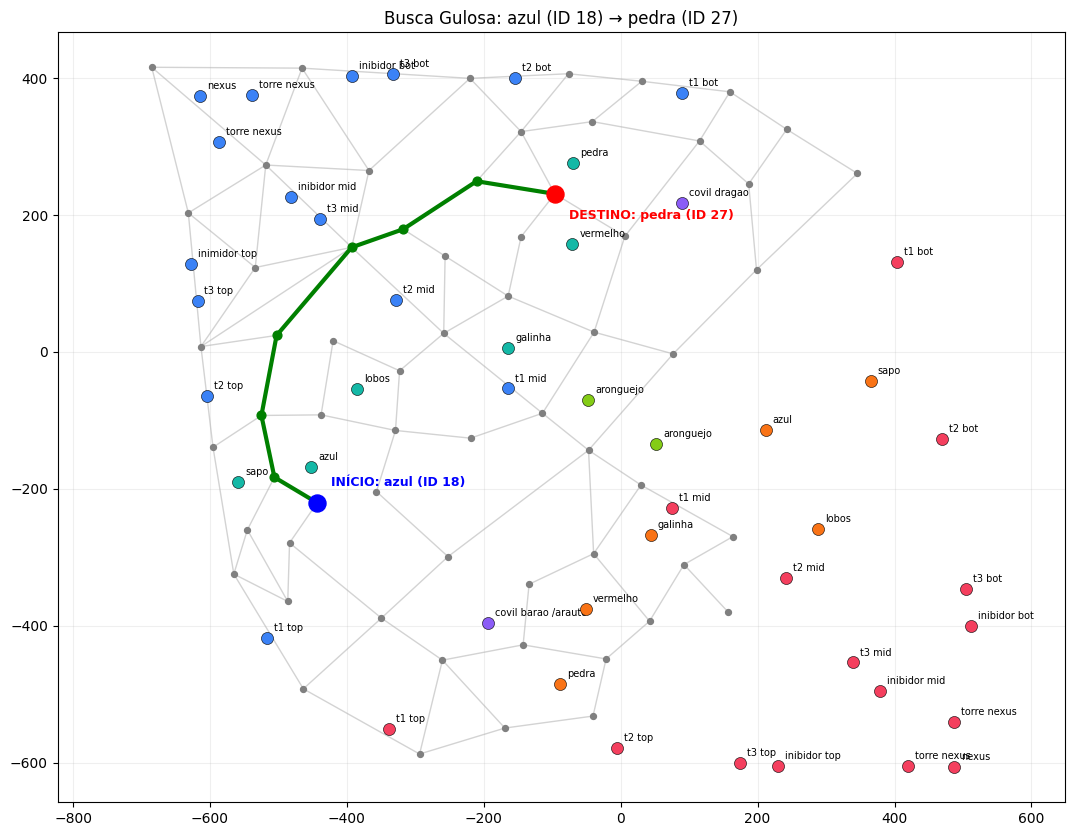

In [9]:
#Para plotar o mapa teve ajuda da IA, que sugeriu a forma de plotar o mapa com as conexões transitáveis, os nós transitáveis, os objetivos e o caminho encontrado pela busca gulosa.
plt.figure(figsize=(13, 10))

# Conexões transitáveis (sem desenhar cada aresta duas vezes)
for origem, vizinhos in grafo.items():
    x1, y1 = coordenadas[origem]
    for destino in vizinhos:
        if origem < destino: # Evita desenhar a mesma aresta duas vezes
            x2, y2 = coordenadas[destino]
            plt.plot([x1, x2], [y1, y2], color="lightgray", linewidth=1, zorder=1)

# Nós transitáveis
for x, y in coordenadas.values():
    plt.scatter(x, y, color="gray", s=18, zorder=2) #Plotando os nós transitáveis com cor cinza e tamanho 18

# Objetivos e estruturas visuais existentes no JSON
for id_no, no in nos.items():
    if id_no not in grafo: #Se o nó não for transitável, ele será plotado com a cor definida no JSON e terá um rótulo associado a ele.
        x, y = no["x"], no["y"]
        plt.scatter(x, y, color=no["color"], s=75, edgecolors="black", linewidths=0.4, zorder=3)
        plt.annotate(no["label"], (x, y), xytext=(5, 5),textcoords="offset points", fontsize=7)

# Caminho encontrado pela busca gulosa
if caminho:
    xs = [coordenadas[no][0] for no in caminho] # Coordenadas X dos nós no caminho
    ys = [coordenadas[no][1] for no in caminho] # Coordenadas Y dos nós no caminho
    plt.plot(xs, ys, color="green", linewidth=3, zorder=4) #Desenhando o caminho encontrado pela busca gulosa com cor verde e largura 3
    plt.scatter(xs, ys, color="green", s=40, zorder=5) #Plotando os nós do caminho com cor verde e tamanho 40
    plt.scatter(*coordenadas[inicio], color="blue", s=150, zorder=6) #Plotando o nó de início com cor azul e tamanho 150
    plt.scatter(*coordenadas[objetivo], color="red", s=150, zorder=6) #Plotando o nó de objetivo com cor vermelha e tamanho 150
    plt.annotate(f"INÍCIO: {origem_escolhida}", coordenadas[inicio],
                 xytext=(10, 12), textcoords="offset points",
                 fontsize=9, fontweight="bold", color="blue")
    plt.annotate(f"DESTINO: {destino_escolhido}", coordenadas[objetivo],
                 xytext=(10, -18), textcoords="offset points",
                 fontsize=9, fontweight="bold", color="red")

plt.title(f"Busca Gulosa: {origem_escolhida} → {destino_escolhido}")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

## 6. Resultados da busca

A seguir, são apresentados o caminho encontrado pela busca gulosa, a validação das conexões e a quantidade de nós expandidos durante a execução.

In [10]:
print("Origem:", origem_escolhida)
print("Destino:", destino_escolhido)

if caminho is None:
    print("Nenhum caminho encontrado.")
else:
    print("Caminho:", " → ".join(nos[no]["label"] for no in caminho))
    print("Caminho válido:", valido)
    print("Quantidade de nós no caminho:", len(caminho))
    print("Quantidade de nós expandidos:", len(expandidos))

Origem: azul (ID 18)
Destino: pedra (ID 27)
Caminho: top_a16 → top_a17 → top_a03 → top_a01 → base_mid → bot_a01 → bot_a07 → bot_a19
Caminho válido: True
Quantidade de nós no caminho: 8
Quantidade de nós expandidos: 7


## 7. Explicação da implementação e considerações finais

**Objetivo.** Demonstrar a aplicação da Busca Gulosa em um problema de navegação sobre um grafo inspirado no mapa de *League of Legends*.

**Representação do ambiente.** O arquivo `mapa_lol.json` fornece os nós, suas coordenadas e as conexões. Os nós cinzas representam posições transitáveis. Os demais identificam monstros, estruturas e outros pontos de referência. Para selecionar um objetivo do jogo, utilizamos o nó transitável mais próximo de sua posição no mapa. O mapa foi feito à mão por meio de um site interativo que permitia modelar um grafo e depois importá-lo para JSON.

**Algoritmo.** A busca gulosa escolhe, a cada etapa, o nó da fronteira com o menor valor de heurística. A heurística usada é a **distância euclidiana em linha reta** entre o nó candidato e o nó de destino. A fronteira é gerenciada por uma **min-heap implementada manualmente** em `heap.py`. A função em `busca_gulosa.py` também controla os nós visitados, registra os nós expandidos e reconstrói o caminho por meio dos predecessores.

**Resultado e validação.** O notebook apresenta os nomes dos nós percorridos, a quantidade de expansões e um gráfico da rota. A validação verifica se **cada par consecutivo do caminho está ligado por uma aresta do grafo**. Essa verificação confirma a validade da rota no modelo representado, mas não garante que o percurso corresponda exatamente à movimentação possível dentro do jogo.

**Limitações.** A busca gulosa usa apenas a estimativa heurística para orientar a exploração, **sem garantir o caminho de menor custo**. Os acessos aos objetivos são escolhidos por proximidade geométrica.